# Example notebook using the IGVF Catalog API to perform comparative analysis between HepG2 MPRA data ([IGVFFI4328UUGV](https://data.igvf.org/tabular-files/IGVFFI4328UUGV/)) and eQTLs from the EBI eQTL Catalogue

In [15]:
import requests
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredText

In [16]:
def paginated(url, page_size=25, max_results=1000, verbose=False):
    ''' This is a utility function to page results from the Catalog API
        use page_size (default = 25 records) and max_results (default=1000 records)
        One query is made per page, up to max_results.
    '''

    page = 0
    found = 'start'
    data = []
    total_found = 0
    request_url = url + "&page=%s&limit=%s" % (page, page_size)
    while(found and len(data) <= max_results):
        if found == 'start':
            found = 0
        res = requests.get(url+ "&page=%s&limit=%s" % (page, page_size)  )
        if res.status_code == 200:
            found = len(res.json())
            total_found = total_found + found
            if verbose:
                print("url: %s page: %s found: %s total: %s" % (request_url, page, found, total_found))
            # last page should be empty
            for doc in res.json():
                data.append(doc)
            page=page+1
        else:
            print(url+ "&page=%s&limit=%s" % (page, page_size)  )
            print(res.text)
            break
    return data

In [17]:
api_host = 'https://catalog-api-dev.demo.igvf.org'

## MPRA

### Retrieve variant-level data from [IGVFFI4328UUGV](https://data.igvf.org/tabular-files/IGVFFI4328UUGV/), the `reporter genomic variant effects` file under analysis set [IGVFDS0160VPYP](https://data.igvf.org/analysis-sets/IGVFDS0160VPYP/)

Experiment summary: electroporated MPRA integrating a reporter library targeting phenotype-associated variants genome-wide associated with 8 phenotypes

In [18]:
variant_mpra_file_id = 'IGVFFI4328UUGV'
url = "%s/api/variants/biosamples?files_fileset=%s&verbose=false" % (api_host, variant_mpra_file_id)
print(url)

byfile = paginated(url, 500, 150_000)
variantMPRA_df = pd.DataFrame(byfile)
print(len(variantMPRA_df))
variantMPRA_df.head(5)

https://catalog-api-dev.demo.igvf.org/api/variants/biosamples?files_fileset=IGVFFI4328UUGV&verbose=false
9017


,variant,biosample,genomic_element,strand,log2FC,DNA_count_ref,DNA_count_alt,RNA_count_ref,RNA_count_alt,postProbEffect,...,significant,neg_log10_pvalue,neg_log10_pvalue_adj,label,method,class,source,source_url,name,files_filesets
0,variants/NC_000001.11:109274794:C:T,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_109274669_109274919...,+,0.023672,17.483082,38.125201,17.117670,38.569902,None,...,False,0.047788,0.025604,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4328...,modulates regulatory activity of,files_filesets/IGVFFI4328UUGV
1,variants/NC_000001.11:109274840:A:C,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_109274715_109274965...,+,1.072027,14.401988,10.463544,18.043459,28.556956,None,...,True,4.745848,3.307715,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4328...,modulates regulatory activity of,files_filesets/IGVFFI4328UUGV
2,variants/NC_000001.11:109274845:C:A,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_109274720_109274970...,+,1.822932,28.536054,23.591688,35.375552,105.790618,None,...,True,12.048067,9.356004,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4328...,modulates regulatory activity of,files_filesets/IGVFFI4328UUGV
3,variants/NC_000001.11:109274846:T:G,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_109274721_109274971...,+,2.145500,9.048433,26.636248,12.526870,160.315341,None,...,True,11.249070,8.623954,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4328...,modulates regulatory activity of,files_filesets/IGVFFI4328UUGV
4,variants/NC_000001.11:109274852:T:G,ontology_terms/EFO_0001187,genomic_elements/MPRA_chr1_109274727_109274977...,+,0.284192,13.841788,3.838581,19.458924,7.619127,None,...,False,0.553978,0.342401,variant effect on regulatory element activity,MPRA,observed data,IGVF,https://data.igvf.org/tabular-files/IGVFFI4328...,modulates regulatory activity of,files_filesets/IGVFFI4328UUGV


In [19]:
variantMPRA_df.columns

Index(['variant', 'biosample', 'genomic_element', 'strand', 'log2FC',
       'DNA_count_ref', 'DNA_count_alt', 'RNA_count_ref', 'RNA_count_alt',
       'postProbEffect', 'CI_lower_95', 'CI_upper_95', 'significant',
       'neg_log10_pvalue', 'neg_log10_pvalue_adj', 'label', 'method', 'class',
       'source', 'source_url', 'name', 'files_filesets'],
      dtype='object')

In [20]:
variant_MPRA_subset = variantMPRA_df[['variant','genomic_element','log2FC','neg_log10_pvalue_adj']].copy()
variant_MPRA_subset.rename(
    columns={
        'genomic_element':'MPRA.genomic_element',
        'log2FC':'MPRA.log2FC',
        'neg_log10_pvalue_adj':'MPRA.neg_log10_pvalue_adj'
    },
    inplace=True
)

## eQTL (Finemapped GTEx Liver eQTLs)

In [21]:
eqtl_file_id = 'IGVFFI1303GKUY'
url = "%s/api/variants/genes?files_fileset=%s" % (api_host, eqtl_file_id)
print(url)
bymethod = paginated(url, 500, 70000)
eqtls_df = pd.DataFrame(bymethod)
print(len(eqtls_df))
eqtls_df.head(5)

https://catalog-api-dev.demo.igvf.org/api/variants/genes?files_fileset=IGVFFI1303GKUY


64744


,gene,sequence_variant,effect_size,neg_log10_pvalue,posterior_inclusion_probability,standard_error,z_score,credible_set_min_r2,method,source,source_url,label,p_value,biological_context,biosample_term,study,name,class,files_filesets
0,genes/ENSG00000260269,variants/NC_000015.10:75330601:G:A,-0.523208,8.426247,0.029930,0.084673,-6.356068,0.308085,eQTL,EBI,ftp://ftp.ebi.ac.uk/pub/databases/spot/eQTL/su...,eQTL,3.747600e-09,liver,ontology_terms/UBERON_0001114,studies/QTS000015,modulates expression of,observed data,files_filesets/IGVFFI1303GKUY
1,genes/ENSG00000262881,variants/NC_000017.11:45990179:T:C,-0.732386,32.405720,0.000375,0.050028,-14.936416,1.000000,eQTL,EBI,ftp://ftp.ebi.ac.uk/pub/databases/spot/eQTL/su...,eQTL,3.928980e-33,liver,ontology_terms/UBERON_0001114,studies/QTS000015,modulates expression of,observed data,files_filesets/IGVFFI1303GKUY
2,genes/ENSG00000197062,variants/NC_000006.12:28110524:G:A,-0.275689,6.328404,0.003509,0.052856,-5.341283,0.256316,eQTL,EBI,ftp://ftp.ebi.ac.uk/pub/databases/spot/eQTL/su...,eQTL,4.694570e-07,liver,ontology_terms/UBERON_0001114,studies/QTS000015,modulates expression of,observed data,files_filesets/IGVFFI1303GKUY
3,genes/ENSG00000262881,variants/NC_000017.11:45664085:C:T,-0.732386,32.405720,0.000375,0.050028,-14.936416,1.000000,eQTL,EBI,ftp://ftp.ebi.ac.uk/pub/databases/spot/eQTL/su...,eQTL,3.928980e-33,liver,ontology_terms/UBERON_0001114,studies/QTS000015,modulates expression of,observed data,files_filesets/IGVFFI1303GKUY
4,genes/ENSG00000147121,variants/NC_000023.11:46551365:G:A,0.298416,11.428737,0.011432,0.040241,7.643088,0.949315,eQTL,EBI,ftp://ftp.ebi.ac.uk/pub/databases/spot/eQTL/su...,eQTL,3.726170e-12,liver,ontology_terms/UBERON_0001114,studies/QTS000015,modulates expression of,observed data,files_filesets/IGVFFI1303GKUY


In [22]:
eqtls_df.columns

Index(['gene', 'sequence_variant', 'effect_size', 'neg_log10_pvalue',
       'posterior_inclusion_probability', 'standard_error', 'z_score',
       'credible_set_min_r2', 'method', 'source', 'source_url', 'label',
       'p_value', 'biological_context', 'biosample_term', 'study', 'name',
       'class', 'files_filesets'],
      dtype='object')

In [23]:
eqtls_subset_df = eqtls_df[['sequence_variant','gene','effect_size','neg_log10_pvalue','posterior_inclusion_probability','z_score']].copy()
eqtls_subset_df.rename(
    columns={
        'sequence_variant': 'variant',
        'gene': 'gene',
        'effect_size': 'eQTL.effect_size',
        'neg_log10_pvalue': 'eQTL.neg_log10_pvalue',
        'posterior_inclusion_probability': 'eQTL.posterior_inclusion_probability',
        'z_score': 'eQTL.z_score'
    },
    inplace=True
)

### Filter eSNP-eGene pairs for variant with top PIP

In [24]:
top_egenes_df = (
    eqtls_subset_df
    .sort_values(
        ["variant", "eQTL.posterior_inclusion_probability"],
        ascending=[True, False]
    )
    .drop_duplicates("variant")
)
top_egenes_df

,variant,gene,eQTL.effect_size,eQTL.neg_log10_pvalue,eQTL.posterior_inclusion_probability,eQTL.z_score
8551,variants/NC_000001.11:100352621:G:C,genes/ENSG00000079335,-0.771591,17.638563,0.955267,-10.005729
19579,variants/NC_000001.11:1004624:A:G,genes/ENSG00000272512,-0.431829,7.014125,0.036105,-5.746130
34378,variants/NC_000001.11:1005429:A:AA,genes/ENSG00000272512,-0.430423,7.032992,0.039040,-5.762045
38575,variants/NC_000001.11:100566449:T:G,genes/ENSG00000181656,-0.668674,13.488175,0.009477,-8.454751
54362,variants/NC_000001.11:100574638:T:C,genes/ENSG00000181656,-0.649265,13.629215,0.013016,-8.504999
...,...,...,...,...,...,...
22655,variants/NC_000023.11:84932597:AAAAA:AAAA,genes/ENSG00000155008,0.291929,6.155867,0.011263,5.241472
21971,variants/NC_000023.11:84932955:A:G,genes/ENSG00000155008,0.310431,7.397394,0.176766,5.857904
36218,variants/NC_000023.11:84934806:A:G,genes/ENSG00000155008,0.284672,6.239036,0.011716,5.267726
63369,variants/NC_000023.11:84935594:C:T,genes/ENSG00000155008,0.291929,6.155867,0.011263,5.241472


## Merge MPRA and eQTL tables and compare effect sizes

In [25]:
mpra_eqtl_df = variant_MPRA_subset.merge(top_egenes_df, on='variant')
mpra_eqtl_df

,variant,MPRA.genomic_element,MPRA.log2FC,MPRA.neg_log10_pvalue_adj,gene,eQTL.effect_size,eQTL.neg_log10_pvalue,eQTL.posterior_inclusion_probability,eQTL.z_score
0,variants/NC_000002.12:232655543:A:T,genomic_elements/MPRA_chr2_232655499_232655749...,-0.164471,0.316208,genes/ENSG00000115468,0.697035,17.904426,0.937199,10.065273
1,variants/NC_000004.12:148059521::T,genomic_elements/MPRA_chr4_148059395_148059645...,-0.155124,0.377753,genes/ENSG00000071205,0.765154,23.738918,0.291755,12.167446
2,variants/NC_000004.12:148061126:C:T,genomic_elements/MPRA_chr4_148060924_148061174...,-0.095761,0.141501,genes/ENSG00000071205,0.762563,23.353297,0.106657,12.034962
3,variants/NC_000004.12:148061407:G:A,genomic_elements/MPRA_chr4_148061282_148061532...,0.306638,1.316654,genes/ENSG00000071205,0.765154,23.738918,0.291755,12.167446
4,variants/NC_000004.12:76495473:A:G,genomic_elements/MPRA_chr4_76495249_76495499_G...,-1.178072,4.369309,genes/ENSG00000138771,-0.399452,8.111881,0.029513,-6.213659
...,...,...,...,...,...,...,...,...,...
387,variants/NC_000009.12:89605005:A:C,genomic_elements/MPRA_chr9_89604894_89605144_G...,-0.195840,0.270727,genes/ENSG00000285907,-0.695894,17.736909,0.055533,-10.016949
388,variants/NC_000016.10:11551156:A:T,genomic_elements/MPRA_chr16_11551130_11551380_...,-0.216029,0.327036,genes/ENSG00000189067,-0.445209,8.646409,0.151118,-6.459463
389,variants/NC_000016.10:28846323:A:G,genomic_elements/MPRA_chr16_28846298_28846548_...,-0.622565,0.973029,genes/ENSG00000251417,-0.333280,6.932937,0.022599,-5.661251
390,variants/NC_000017.11:48895502:C:T,genomic_elements/MPRA_chr17_48895377_48895627_...,0.459673,1.719007,genes/ENSG00000289021,-0.527303,11.210688,0.008345,-7.511141


In [26]:
sig_df = mpra_eqtl_df[(mpra_eqtl_df['MPRA.neg_log10_pvalue_adj'] > 1) & (mpra_eqtl_df['eQTL.posterior_inclusion_probability'] > 0.1)] # pvalue_adj<0.01
sig_pearson = pearsonr(sig_df['MPRA.log2FC'], sig_df['eQTL.effect_size'])
sig_spearman = spearmanr(sig_df['MPRA.log2FC'], sig_df['eQTL.effect_size'])
sig_concordance = (sig_df['MPRA.log2FC'] * sig_df['eQTL.effect_size'] > 0).mean() * 100
all_pearson = pearsonr(mpra_eqtl_df['MPRA.log2FC'], mpra_eqtl_df['eQTL.effect_size'])
all_spearman = spearmanr(mpra_eqtl_df['MPRA.log2FC'], mpra_eqtl_df['eQTL.effect_size'])
all_concordance = (mpra_eqtl_df['MPRA.log2FC'] * mpra_eqtl_df['eQTL.effect_size'] > 0).mean() * 100

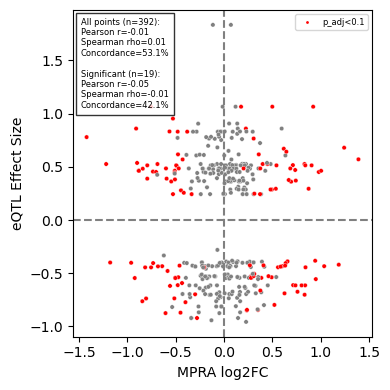

In [29]:
fig, ax = plt.subplots(figsize=(4, 4))

tewhey_legend_element = [Line2D([0], [0], marker='o', color='w', 
                             markerfacecolor='red', markersize=3, 
                             label='p_adj<0.1')]

sns.scatterplot(data=mpra_eqtl_df, 
                x='MPRA.log2FC', 
                y='eQTL.effect_size', 
                s=10, 
                ax=ax, 
                hue=(mpra_eqtl_df['MPRA.neg_log10_pvalue_adj'] > 1), 
                palette={True: 'red', False: 'grey'},
                legend=False)
ax.legend(handles=tewhey_legend_element, title=None, fontsize=6)
ax.axvline(0, color='grey', linestyle='--')
ax.axhline(0, color='grey', linestyle='--')
ax.set_xlabel('MPRA log2FC')
ax.set_ylabel('eQTL Effect Size')
anch = AnchoredText(
        f"All points (n={len(mpra_eqtl_df)}):\n"
        f"Pearson r={all_pearson[0]:.2f}\n"
        f"Spearman rho={all_spearman[0]:.2f}\n"
        f"Concordance={all_concordance:.1f}%\n\n"
        f"Significant (n={len(sig_df)}):\n"
        f"Pearson r={sig_pearson[0]:.2f}\n"
        f"Spearman rho={sig_spearman[0]:.2f}\n"
        f"Concordance={sig_concordance:.1f}%",
        loc='upper left', prop=dict(size=6)
)
anch.patch.set_boxstyle("Square,pad=0.2")
anch.patch.set_facecolor('white')
anch.patch.set_alpha(0.8)
ax.add_artist(anch)

plt.tight_layout()
# plt.savefig('plots/gtex_blood_eqtl_tewhey.png', dpi=300)
plt.show()